In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = load_diabetes()

In [3]:
df = pd.DataFrame(data.data, columns=data.feature_names)
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [4]:
X = df[["bmi"]]
y = data.target

In [5]:
X_train, X_test, y_train,y_test = train_test_split(X,y,random_state=42,test_size = 0.2)

In [6]:
degree = [1, 2, 3, 5, 10]
result = []

In [7]:
for d in degree:

    model = make_pipeline(
        PolynomialFeatures(degree=d),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Evaluation
    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)
    rmse = np.sqrt(test_mse)
    r2 = r2_score(y_test, test_pred)

    result.append([d, train_mse, test_mse, rmse, r2])

In [8]:
# Display results
df = pd.DataFrame(result, columns=[
    'Degree', 'Train MSE', 'Test MSE', 'RMSE', 'R2'
])

In [9]:
print(df.round(2))

   Degree  Train MSE  Test MSE   RMSE    R2
0       1    3854.11   4061.83  63.73  0.23
1       2    3849.33   4085.03  63.91  0.23
2       3    3848.45   4064.44  63.75  0.23
3       5    3823.76   4085.85  63.92  0.23
4      10    3724.61   4315.53  65.69  0.19


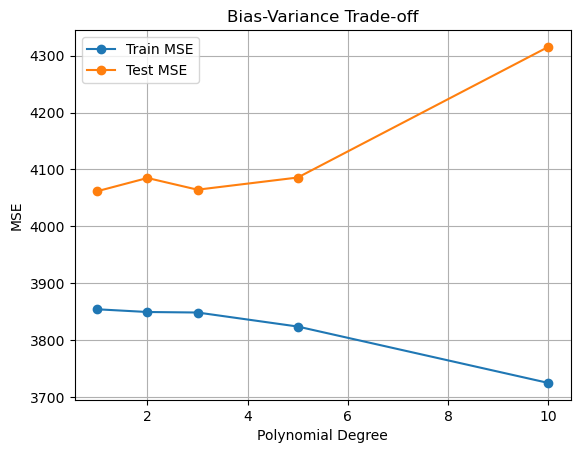

In [10]:
# Visualization
plt.plot(degree, df['Train MSE'], marker='o', label='Train MSE')
plt.plot(degree, df['Test MSE'], marker='o', label='Test MSE')

plt.xlabel('Polynomial Degree')
plt.ylabel('MSE')
plt.title('Bias-Variance Trade-off')
plt.legend()
plt.grid()
plt.show()
